In [ ]:
import torch
import matplotlib.pyplot as plt
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np
from tqdm import tqdm
import os

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [ ]:
tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(256),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

full_ds = ConcatDataset([
    datasets.Flowers102("data", split=s, download=True, transform=tf)
    for s in ["train", "val", "test"]
])
print("Total:", len(full_ds))

100%|██████████| 345M/345M [00:14<00:00, 24.5MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.92MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 37.4MB/s]


Total: 8189


In [ ]:
train_ds, test_ds = random_split(
    full_ds, [7000, len(full_ds) - 7000],
    generator=torch.Generator().manual_seed(0))

batch_size = 2

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

x, y = train_ds[0]
print("Train:", len(train_ds), "| Test:", len(test_ds))
print("Forma (C,H,W):", x.shape)

Train: 7000 | Test: 1189
Forma (C,H,W): torch.Size([3, 256, 256])


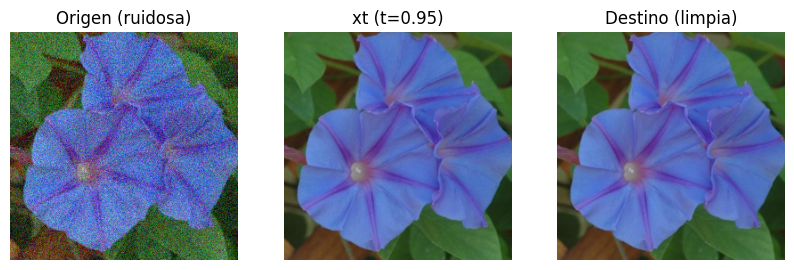

In [ ]:
#se hace el calculo  del mapeo de transporte por batch para eficiencia
def sample_flow_batch(x0, x1):
    B = x0.size(0)   # da el número de imágenes en el lote
    t = torch.rand(B, 1, 1, 1, device=x0.device)  #tiempo aleatorio t (entre 0 y 1) para cada imagen del batch.
    xt = (1 - t) * x0 + t * x1 # Trayectoria correcta
    v_true = x1 - x0  # campo de velocidades verdadero
    return x0, x1, xt, t, v_true

sigma = 0.2
img, _ = train_ds[0]
x1 = img.unsqueeze(0).to(device)                 # destino: imagen limpia
x0 = x1 + sigma * torch.randn_like(x1)           # origen: imagen con ruido

x0, x1, xt, t, v = sample_flow_batch(x0, x1)


#############################################################################################################################

def to_img(x):
    return (x[0].cpu() * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
plt.figure(figsize=(10, 3.5))
for i, (im, title) in enumerate([(x0, "Origen (ruidosa)"),
                                 (xt, f"xt (t={t.item():.2f})"),
                                 (x1, "Destino (limpia)")]):
    plt.subplot(1, 3, i + 1)
    plt.title(title)
    plt.imshow(to_img(im))
    plt.axis("off")
plt.show()    # 102

In [ ]:
#################################################
# EN QUE MOMENTO ESTA
#################################################
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2

        emb_factor = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb_factor)

        emb = t * emb
        emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)

        return emb


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.conv3 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_mlp = nn.Linear(time_dim, out_ch)

    def forward(self, x, t_emb):
        h = F.silu(self.conv1(x))
        time_emb = self.time_mlp(t_emb)
        time_emb = time_emb[:, :, None, None]
        h = h + time_emb
        h = F.silu(self.conv2(h))
        h = h + time_emb
        h = F.silu(self.conv3(h))
        return h


class UNetRectifiedFlow(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()

        # ---- Time embedding ----
        self.time_embedding = SinusoidalTimeEmbedding(time_dim)
        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, time_dim),
            nn.ReLU()
        )

        # ---- Encoder ----
        self.enc1 = ConvBlock(3, 32, time_dim)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ConvBlock(32, 64, time_dim)
        self.pool2 = nn.MaxPool2d(2)

        # ---- Bottleneck ----
        self.bottleneck = ConvBlock(64, 128, time_dim)

        # ---- Decoder ----
        self.up1 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(128, 64, 3, padding=1)
        )
        self.dec1 = ConvBlock(128, 64, time_dim)   # 64 + 64 skip

        self.up2 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(64, 32, 3, padding=1)
        )
        self.dec2 = ConvBlock(64, 32, time_dim)   # 32 + 32 skip

        self.final = nn.Conv2d(32, 3, 3, padding=1)

    def forward(self, x, t):
        B = x.size(0)

        # ---- Time embedding ----
        t = t.view(B, 1)
        t_emb = self.time_embedding(t)
        t_emb = self.time_mlp(t_emb)

        # ---- Encoder ----
        e1 = self.enc1(x, t_emb)        # (B,32,256,256)
        p1 = self.pool1(e1)             # (B,32,128,128)

        e2 = self.enc2(p1, t_emb)       # (B,64,128,128)
        p2 = self.pool2(e2)             # (B,64,64,64)

        # ---- Bottleneck ----
        b = self.bottleneck(p2, t_emb)  # (B,128,64,64)

        # ---- Decoder ----
        u1 = self.up1(b)                # (B,64,128,128)
        u1 = torch.cat([u1, e2], dim=1) # (B,128,128,128
        d1 = self.dec1(u1, t_emb)       # (B,64,128,128)

        u2 = self.up2(d1)               # (B,32,256,256)
        u2 = torch.cat([u2, e1], dim=1) # (B,64,256,256)
        d2 = self.dec2(u2, t_emb)       # (B,32,256,256)

        return self.final(d2)           # (B,3,256,256)

model = UNetRectifiedFlow().to(device)

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
    betas=(0.9, 0.999),
    eps=1e-8,
    weight_decay=0.0,
    amsgrad=False
)

# Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',        # queremos minimizar el loss
    factor=0.5,        # reduce el LR a la mitad
    patience=3,        # espera 3 épocas sin mejora
    threshold=1e-3,    # mínima mejora significativa
)

epochs = 20
sigma = 0.3

for epoch in range(epochs):
    model.train()  # 1. Ponemos el modelo en "modo entrenamiento".
    total_loss = 0.0  # Acumulador de error promedio al final de la época

    loop = tqdm(train_loader, leave=False) # tqdm barra de progreso

    for x1_batch, _ in loop: # 2. Iteracion sobre lotes (batches)
        x1_batch = x1_batch.to(device)                             # destino: x1
        x0_batch = x1_batch + sigma * torch.randn_like(x1_batch)   # origen: x0

        x0, x1, xt, t, v_true = sample_flow_batch(x0_batch, x1_batch) # 3. Obtenemos el punto intermedio (xt), el tiempo (t) y la dirección real (v_true)

        v_pred = model(xt, t) # 4. Predicción: Le damos al modelo la imagen intermedia 'xt' y le decimos en qué momento 't' está.
        loss = torch.mean((v_pred - v_true) ** 2) # Funcion de costo
        # 5. Actualización de pesos
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
        loop.set_postfix(loss=total_loss/(loop.n+1))

    avg_loss = total_loss / len(train_loader)
    scheduler.step(avg_loss)

    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1} | Loss: {avg_loss:.6f} | LR: {current_lr:.6f}")


KeyboardInterrupt: 